# Unit 4 — Memvalidasi Data
**Kode unit:** J.62DMI00.006.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini memvalidasi kualitas data pada enam dimensi — kelengkapan, keunikan, validitas domain, kewajaran nilai, keselarasan kalender, dan integritas waktu (*point-in-time*). Setiap temuan dicatat dalam **log anomali** yang dipakai langsung oleh proses pembersihan di Unit 6.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

In [2]:
df = pd.read_csv(RAW, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
VARS = ['OIL', 'GOLD', 'USDIDR', 'SP500', 'IHSG', 'VIX', 'CPI', 'BI_rate', 'US_rate']
n_rows, n_cells = len(df), len(df) * len(VARS)
anomalies = []   # log baris-per-baris: Date, variabel, nilai, masalah, tindakan
print(f'{n_rows:,} baris, {n_cells:,} sel nilai diperiksa')

4,277 baris, 38,493 sel nilai diperiksa


## 1. Kelengkapan (*completeness*)

In [3]:
missing = df[VARS].isna().sum()
display(missing.to_frame('Jumlah kosong').T)
rows_missing = df[df[VARS].isna().any(axis=1)]
display(rows_missing)
for _, row in rows_missing.iterrows():
    anomalies.append({'Date': row.Date, 'variabel': 'SEMUA_PASAR', 'nilai': np.nan,
                      'masalah': 'Nilai pasar kosong (libur Tahun Baru di semua bursa)', 'tindakan': 'hapus_baris'})
completeness = (1 - missing.sum() / n_cells) * 100
print(f'Kelengkapan sel: {completeness:.3f}%')

,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate
Jumlah kosong,1,1,0,1,1,1,0,0,0


,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate
0,2010-01-01,NaN,NaN,"9,385.5996",NaN,NaN,NaN,5.1342,6.5000,0.1100


Kelengkapan sel: 99.987%


## 2. Keunikan (*uniqueness*)

In [4]:
dup_dates = int(df.Date.duplicated().sum())
dup_rows = int(df.duplicated().sum())
uniqueness = (1 - dup_dates / n_rows) * 100
print(f'Tanggal duplikat: {dup_dates} | baris duplikat penuh: {dup_rows} | urutan tanggal naik: {df.Date.is_monotonic_increasing}')

Tanggal duplikat: 0 | baris duplikat penuh: 0 | urutan tanggal naik: True


## 3. Validitas domain (aturan rentang nilai)

In [5]:
rules = [
    ('Tanggal pada hari kerja (Sen–Jum)', 'Date', df.Date.dt.dayofweek < 5),
    ('OIL > 0', 'OIL', df.OIL > 0),
    ('GOLD > 0', 'GOLD', df.GOLD > 0),
    ('USDIDR > 0', 'USDIDR', df.USDIDR > 0),
    ('SP500 > 0', 'SP500', df.SP500 > 0),
    ('IHSG > 0', 'IHSG', df.IHSG > 0),
    ('0 < VIX < 100', 'VIX', df.VIX.between(0, 100, inclusive='neither')),
    ('0 ≤ BI_rate ≤ 25', 'BI_rate', df.BI_rate.between(0, 25)),
    ('0 ≤ US_rate ≤ 25', 'US_rate', df.US_rate.between(0, 25)),
    ('-5 ≤ CPI ≤ 30', 'CPI', df.CPI.between(-5, 30)),
]
res, n_checked, n_viol = [], 0, 0
for name, col, ok in rules:
    present = df[col].notna()
    viol = df.loc[present & ~ok, ['Date', col]]
    n_checked += int(present.sum())
    n_viol += len(viol)
    contoh = '-' if viol.empty else ', '.join(f'{d:%Y-%m-%d} ({v:.2f})' for d, v in zip(viol.Date, viol[col]))
    res.append({'Aturan': name, 'Diperiksa': int(present.sum()), 'Pelanggaran': len(viol), 'Contoh': contoh})
display(pd.DataFrame(res))
validity = (1 - n_viol / n_checked) * 100

for _, row in df[df.OIL <= 0].iterrows():
    anomalies.append({'Date': row.Date, 'variabel': 'OIL', 'nilai': row.OIL,
                      'masalah': 'Harga minyak negatif (peristiwa nyata: kontrak WTI kedaluwarsa); return % tidak terdefinisi',
                      'tindakan': 'ganti_nan_ffill'})
print(f'Validitas domain: {validity:.3f}% sel lolos aturan')

,Aturan,Diperiksa,Pelanggaran,Contoh
0,Tanggal pada hari kerja (Sen–Jum),4277,0,-
1,OIL > 0,4276,1,2020-04-20 (-37.63)
2,GOLD > 0,4276,0,-
3,USDIDR > 0,4277,0,-
4,SP500 > 0,4276,0,-
5,IHSG > 0,4276,0,-
6,0 < VIX < 100,4276,0,-
7,0 ≤ BI_rate ≤ 25,4277,0,-
8,0 ≤ US_rate ≤ 25,4277,0,-
9,-5 ≤ CPI ≤ 30,4277,0,-


Validitas domain: 99.998% sel lolos aturan


Harga minyak **−37,63 USD** pada 20 April 2020 adalah **peristiwa pasar yang nyata** (kontrak berjangka WTI bulan Mei
2020 menjelang jatuh tempo), bukan salah ketik. Namun nilai negatif membuat *return* persentase tidak bermakna
(misalnya −306%), sehingga perlu penanganan khusus.

## 4. Kewajaran nilai: kutipan USD/IDR yang janggal

Tiga aturan deteksi dipakai:

1. **Penyimpangan dari median (varian *Hampel filter*)** — nilai yang menyimpang > 4% dari **median bergulir terpusat
   21 hari**. Jendela 21 hari dipilih agar median tetap stabil walaupun beberapa kutipan rusak berdekatan.
2. **Kutipan "macet"** — nilai yang identik persis muncul pada banyak rangkaian tanggal yang terpisah. Pada kurs mengambang,
   kutipan yang sama wajar berulang beberapa kali selama bertahun-tahun, tetapi tidak puluhan kali dalam satu tahun.
3. **Lonjak-lalu-kembali** — kurs bergerak > 3% dalam sehari, lalu > 3% berlawanan arah keesokan harinya hingga kembali
   ke dalam ±1% dari level sebelum lonjakan. Pola ini khas kesalahan kutipan satu hari, bukan pergerakan pasar.

*Catatan iterasi:* aturan ketiga ditambahkan setelah uji verifikasi di Unit 6 pada iterasi pertama **gagal**: kutipan
19 Jun 2025 (15.598,5 di antara 16.275 dan 16.390) lolos dari dua aturan pertama. Ini contoh siklus CRISP-DM yang
berulang — temuan di tahap pembersihan memperbaiki tahap validasi.

Nilai USD/IDR dengan rangkaian kemunculan terpisah terbanyak:


,rangkaian terpisah
"9,612.4500",26
"13,303.0000",6
"13,320.0000",6
"13,296.0000",6
"13,318.0000",6


Total ditandai: 37 | terdeteksi per aturan: {'median': 15, 'macet': 28, 'lonjak-kembali': 11}
Hanya tertangkap aturan lonjak-kembali: ['2011-10-05', '2020-01-28', '2025-06-19']


,Date,USDIDR,median_21h,deviasi_pct,aturan
0,2010-11-01,888.1100,"8,906.7000",-90.0000,median + lonjak-kembali
1,2011-10-05,"8,622.0000","8,880.0000",-2.9000,lonjak-kembali
2,2012-02-07,892.0000,"8,965.0000",-90.1000,median + lonjak-kembali
3,2012-11-26,"9,612.4502","9,590.1000",0.2000,macet
4,2012-12-10,"9,612.4502","9,601.8000",0.1000,macet
5,2012-12-17,"9,612.4502","9,611.8000",0.0000,macet
6,2012-12-31,"9,612.4502","9,624.0000",-0.1000,macet
7,2013-01-14,"9,612.4502","9,621.6000",-0.1000,macet
8,2013-01-28,"9,612.4502","9,621.8000",-0.1000,macet
9,2013-02-04,"9,612.4502","9,631.6000",-0.2000,macet


,Date,USDIDR,ditandai
0,2020-03-16,"14,635.0225",False
1,2020-03-17,"15,192.0000",False
2,2020-03-18,"14,955.7881",False
3,2020-03-19,"15,474.5000",False
4,2020-03-20,"15,908.0000",False
5,2020-03-23,"15,766.2471",False
6,2020-03-24,"16,504.8008",False
7,2020-03-25,"16,216.5000",False
8,2020-03-26,"16,447.7207",False
9,2020-03-27,"16,218.6367",False


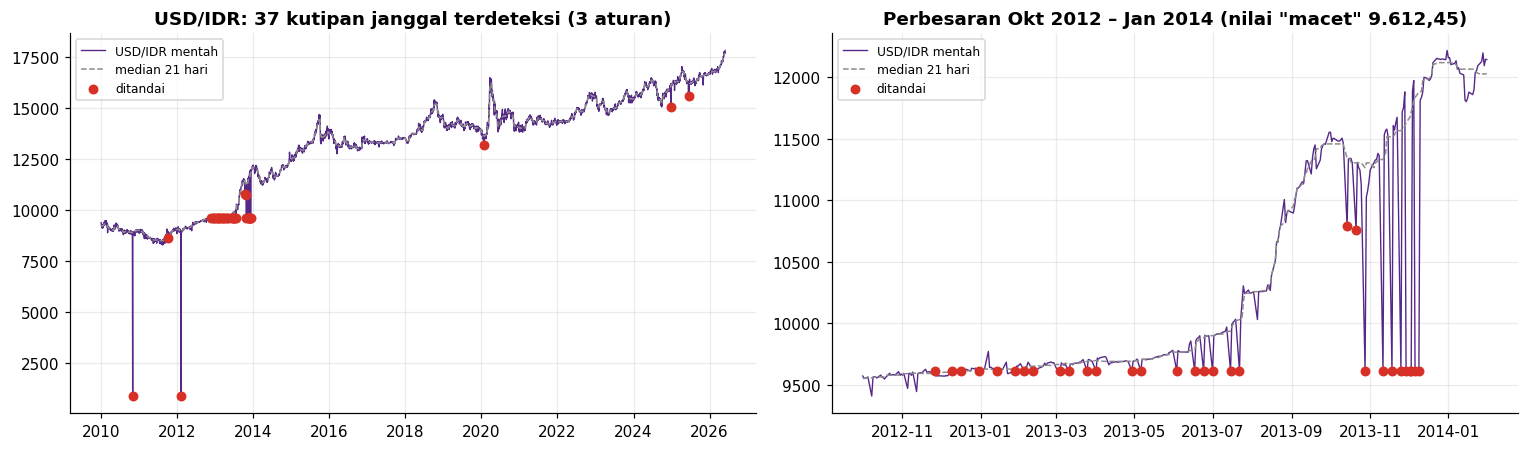

In [6]:
WINDOW, THRESH = 21, 0.04
med = df.USDIDR.rolling(WINDOW, center=True, min_periods=5).median()
dev = df.USDIDR / med - 1
rule_hampel = dev.abs() > THRESH

key = df.USDIDR.round(2)
runs = pd.Series({val: int((np.diff(np.sort(np.asarray(idx))) > 1).sum() + 1)
                  for val, idx in df.groupby(key).groups.items()}).sort_values(ascending=False)
print('Nilai USD/IDR dengan rangkaian kemunculan terpisah terbanyak:')
display(runs.head(5).rename('rangkaian terpisah').to_frame())
STALE_MIN_RUNS = 10   # nilai normal paling banyak berulang 6 kali; ambang 10 memisahkan dengan jelas
stale_vals = runs[runs >= STALE_MIN_RUNS].index
rule_stale = key.isin(stale_vals)

u = df.USDIDR
r_in, r_out, r_net = u / u.shift(1) - 1, u.shift(-1) / u - 1, u.shift(-1) / u.shift(1) - 1
rule_spike = (r_in.abs() > 0.03) & (r_out.abs() > 0.03) & (np.sign(r_in) != np.sign(r_out)) & (r_net.abs() < 0.01)
glitch = rule_hampel | rule_stale | rule_spike

rules_hit = pd.DataFrame({'median': rule_hampel, 'macet': rule_stale, 'lonjak-kembali': rule_spike})[glitch]
gl = df.loc[glitch, ['Date', 'USDIDR']].assign(
    median_21h=med[glitch].round(1), deviasi_pct=(dev[glitch] * 100).round(1),
    aturan=rules_hit.apply(lambda r: ' + '.join(r.index[r.values]), axis=1))
print(f'Total ditandai: {int(glitch.sum())} | terdeteksi per aturan:', rules_hit.sum().to_dict())
print('Hanya tertangkap aturan lonjak-kembali:', df.Date[rule_spike & ~rule_hampel & ~rule_stale].dt.strftime('%Y-%m-%d').tolist())
display(gl.reset_index(drop=True))
for _, row in gl.iterrows():
    anomalies.append({'Date': row.Date, 'variabel': 'USDIDR', 'nilai': row.USDIDR,
                      'masalah': f'Kutipan kurs janggal ({row.aturan}); deviasi {row.deviasi_pct:+.1f}% dari median 21 hari',
                      'tindakan': 'ganti_nan_ffill'})

# kontrol: pergerakan ekstrem yang NYATA tidak boleh ikut tertandai (krisis COVID-19, Maret 2020)
covid = df[(df.Date >= '2020-03-16') & (df.Date <= '2020-03-27')][['Date', 'USDIDR']].assign(ditandai=glitch)
display(covid.reset_index(drop=True))
plausibility = (1 - glitch.sum() / n_rows) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (a, b) in zip(axes, [('2010-01-01', '2026-06-01'), ('2012-10-01', '2014-01-31')]):
    m = (df.Date >= a) & (df.Date <= b)
    ax.plot(df.Date[m], df.USDIDR[m], color='#542788', lw=0.9, label='USD/IDR mentah')
    ax.plot(df.Date[m], med[m], color=C_GREY, lw=1, ls='--', label='median 21 hari')
    ax.scatter(df.Date[m & glitch], df.USDIDR[m & glitch], color=C_DOWN, s=30, zorder=3, label='ditandai')
    ax.legend(fontsize=8)
axes[0].set_title(f'USD/IDR: {int(glitch.sum())} kutipan janggal terdeteksi (3 aturan)')
axes[1].set_title('Perbesaran Okt 2012 – Jan 2014 (nilai "macet" 9.612,45)')
plt.tight_layout()
plt.savefig(FIG / '04_usdidr_glitches.png')
plt.show()

Pada contoh kontrol, kenaikan kurs ke ±16.500 pada 24 Maret 2020 (krisis COVID-19) **tidak** ditandai — metode
membedakan kesalahan kutipan dari pergerakan nyata yang berkelanjutan.

**Keterbatasan:** penyimpangan kecil (< 4%) yang tidak berulang mungkin masih tersisa. Dampaknya dibatasi oleh
*winsorization* fitur pada Unit 7.

## 5. Keselarasan kalender: hari libur BEI

Data memakai kalender hari kerja gabungan. Pada hari libur BEI (mis. Idulfitri), nilai IHSG **disalin** dari hari
sebelumnya sehingga tampak "tidak berubah". Jika dibiarkan, hari-hari tersebut akan menghasilkan return 0% palsu.

Hari IHSG tidak berubah (libur BEI): 300 dari 4,277 baris
Contoh rangkaian libur Idulfitri 2010: ['08-09', '09-09', '10-09', '13-09', '14-09']
Nilai disalin pada variabel lain (libur pasar masing-masing): {'SP500': 151, 'VIX': 168, 'OIL': 164, 'GOLD': 164, 'USDIDR': 102}


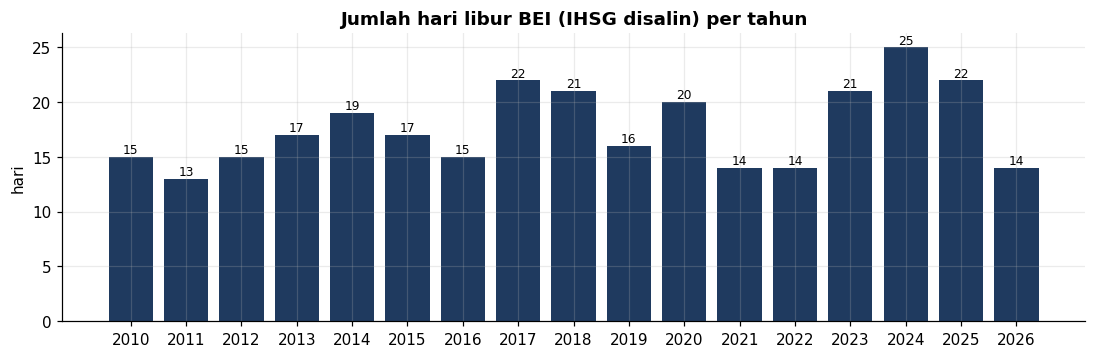

In [7]:
stale = df.IHSG.diff().eq(0)
st = df.loc[stale, ['Date', 'IHSG']]
for _, row in st.iterrows():
    anomalies.append({'Date': row.Date, 'variabel': 'IHSG', 'nilai': row.IHSG,
                      'masalah': 'IHSG sama persis dengan hari sebelumnya (hari libur BEI, nilai disalin)',
                      'tindakan': 'hapus_baris'})
print(f'Hari IHSG tidak berubah (libur BEI): {int(stale.sum())} dari {n_rows:,} baris')
print('Contoh rangkaian libur Idulfitri 2010:', st[(st.Date >= '2010-09-01') & (st.Date <= '2010-09-30')].Date.dt.strftime('%d-%m').tolist())

us_stale = {c: int(df[c].diff().eq(0).sum()) for c in ['SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR']}
print('Nilai disalin pada variabel lain (libur pasar masing-masing):', us_stale)
calendar_align = (1 - stale.sum() / n_rows) * 100

per_year = st.groupby(st.Date.dt.year).size()
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(per_year.index.astype(str), per_year.values, color=C_NAVY)
for x, v in zip(per_year.index.astype(str), per_year.values):
    ax.text(x, v + 0.3, str(v), ha='center', fontsize=8)
ax.set_title('Jumlah hari libur BEI (IHSG disalin) per tahun'); ax.set_ylabel('hari')
plt.savefig(FIG / '04_idx_holidays.png')
plt.show()

Nilai yang disalin pada variabel AS/komoditas (libur pasar AS) **bukan kesalahan**: pada hari itu memang tidak ada
informasi baru, sehingga return 0% adalah representasi yang benar.

Pergerakan IHSG ekstrem (> 5% sehari) juga diperiksa terhadap peristiwa yang diketahui — semuanya merupakan kejadian
pasar nyata sehingga **dipertahankan**:

In [8]:
ih = df.loc[~stale, ['Date', 'IHSG']].dropna().copy()
ih['ret'] = ih.IHSG.pct_change() * 100
events = {
    '2011-09-22': 'Aksi jual global (kekhawatiran resesi & krisis utang Eropa)',
    '2013-08-19': 'Taper tantrum',
    '2020-03-09': 'Pandemi COVID-19 & perang harga minyak',
    '2020-03-12': 'Pandemi COVID-19',
    '2020-03-19': 'Pandemi COVID-19',
    '2020-03-26': 'Rebound setelah paket stimulus AS',
    '2020-09-10': 'Pengetatan kembali PSBB Jakarta',
    '2025-04-08': 'Hari pertama setelah libur Lebaran; kebijakan tarif AS',
}
big = ih[ih.ret.abs() > 5].copy()
big['keterangan'] = big.Date.dt.strftime('%Y-%m-%d').map(events).fillna('Volatilitas tinggi (dipertahankan)')
big['Date'] = big.Date.dt.strftime('%d %b %Y')
display(big.rename(columns={'Date': 'Tanggal', 'ret': 'Return (%)'}).reset_index(drop=True))

,Tanggal,IHSG,Return (%),keterangan
0,26 May 2010,"2,696.6750",7.2654,Volatilitas tinggi (dipertahankan)
1,22 Sep 2011,"3,369.0122",-8.8804,Aksi jual global (kekhawatiran resesi & krisis...
2,03 Oct 2011,"3,348.5776",-5.6445,Volatilitas tinggi (dipertahankan)
3,19 Aug 2013,"4,313.3501",-5.5845,Taper tantrum
4,09 Mar 2020,"5,136.8091",-6.5787,Pandemi COVID-19 & perang harga minyak
5,12 Mar 2020,"4,895.7480",-5.0126,Pandemi COVID-19
6,19 Mar 2020,"4,105.4219",-5.2013,Pandemi COVID-19
7,26 Mar 2020,"4,338.9038",10.1907,Rebound setelah paket stimulus AS
8,10 Sep 2020,"4,891.4609",-5.0087,Pengetatan kembali PSBB Jakarta
9,08 Apr 2025,"5,996.1421",-7.9021,Hari pertama setelah libur Lebaran; kebijakan ...


## 6. Integritas waktu (*point-in-time*)

Sebuah nilai hanya boleh dipakai pada tanggal ketika nilai itu **sudah diketahui publik**. Kita periksa kapan
variabel makro berubah.

In [9]:
first_day = list(df.groupby(df.Date.dt.to_period('M')).Date.min())   # hari kerja pertama tiap bulan
pit = []
for c in ['CPI', 'BI_rate', 'US_rate']:
    s = df[c]
    ch = s.ne(s.shift()); ch.iloc[0] = False
    cp = df.loc[ch, 'Date']
    on_first = cp.isin(first_day)
    pit.append({'Variabel': c, 'Jumlah perubahan': len(cp),
                'Di hari kerja pertama bulan': f'{on_first.mean() * 100:.0f}%',
                'Di bulan Januari': f'{cp.dt.month.eq(1).mean() * 100:.0f}%',
                'Perubahan pertama di luar awal bulan': cp[~on_first].min().strftime('%Y-%m-%d') if (~on_first).any() else '-',
                'Contoh': ', '.join(cp.dt.strftime('%Y-%m-%d').head(3))})
display(pd.DataFrame(pit))

cpi_2026 = df.loc[df.Date.dt.year == 2026, 'CPI'].unique()
print(f'Nilai CPI yang sudah tercantum untuk 2026 (data berakhir {df.Date.max():%d %b %Y}): {cpi_2026}')

,Variabel,Jumlah perubahan,Di hari kerja pertama bulan,Di bulan Januari,Perubahan pertama di luar awal bulan,Contoh
0,CPI,16,100%,100%,-,"2011-01-03, 2012-01-02, 2013-01-01"
1,BI_rate,48,23%,4%,2016-04-21,"2011-02-01, 2011-10-03, 2011-11-01"
2,US_rate,131,100%,9%,-,"2010-02-01, 2010-03-01, 2010-04-01"


Nilai CPI yang sudah tercantum untuk 2026 (data berakhir 29 May 2026): [3.55]


**Interpretasi:**

- **`CPI`** selalu berubah pada hari kerja pertama Januari dan nilainya konsisten dengan inflasi rata-rata **satu tahun
  penuh**. Nilai tahun 2010 sudah tercantum sejak 1 Januari 2010, padahal angka tahunan baru dapat diketahui setelah
  tahunnya berakhir → **look-ahead bias**. Untuk 2026 pun sudah tercantum nilai tahunan walaupun tahunnya belum selesai.
  Selain itu CPI hanya memiliki 17 nilai berbeda, sehingga bagi model berbasis pohon ia cenderung menjadi "penanda tahun"
  (risiko *overfitting*). → **Dikeluarkan dari fitur (Unit 5).**
- **`US_rate`** selalu berubah pada hari kerja pertama bulan; nilainya (mis. 0,11 → 0,13 → 0,16 pada awal 2010)
  konsisten dengan **rata-rata bulanan** suku bunga Fed funds efektif, yang baru diketahui setelah bulan berakhir.
- **`BI_rate`** memiliki dua rezim: hingga awal 2016 berubah di awal bulan (nilai bulanan "ditempel" sejak tanggal 1,
  padahal keputusan diumumkan di tengah bulan), dan sejak 21 April 2016 berubah tepat pada tanggal pengumuman kebijakan.
- → Untuk kedua suku bunga diterapkan **satu aturan konservatif: gunakan nilai yang berlaku pada akhir bulan
  sebelumnya** (Unit 6). Aturan ini menjamin tidak ada informasi yang dipakai sebelum dipublikasikan.

## 7. Kartu skor kualitas dan log anomali

,Dimensi,Ukuran,Skor (%),Status,Tindakan (Unit 5–6)
0,Kelengkapan,Sel tidak kosong,99.9870,Baik,Hapus baris 2010-01-01
1,Keunikan,Tanggal tidak duplikat,100.0000,Baik,-
2,Validitas domain,Sel lolos aturan rentang,99.9977,Baik,Tangani harga OIL negatif
3,Kewajaran nilai,Baris USD/IDR wajar,99.1349,Perlu tindakan,Koreksi kutipan USD/IDR janggal
4,Keselarasan kalender,Baris = hari bursa BEI,92.9857,Perlu tindakan,Hapus hari libur BEI
5,Integritas waktu,Variabel bebas look-ahead,66.6667,Perlu tindakan,Keluarkan CPI; suku bunga = nilai akhir bulan ...


,,jumlah baris
variabel,tindakan,
IHSG,hapus_baris,300
OIL,ganti_nan_ffill,1
SEMUA_PASAR,hapus_baris,1
USDIDR,ganti_nan_ffill,37


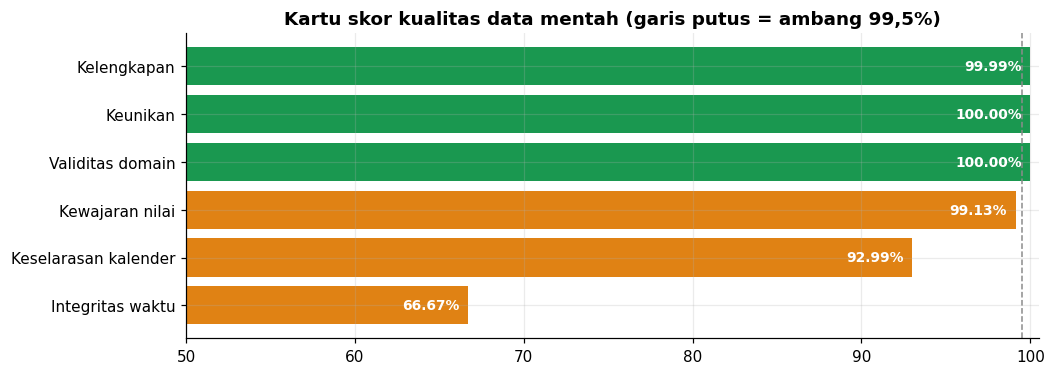

In [10]:
pit_ok = 6 / 9 * 100   # 6 variabel harian aman; CPI, BI_rate, US_rate berisiko look-ahead
score = pd.DataFrame([
    ('Kelengkapan', 'Sel tidak kosong', completeness, 'Hapus baris 2010-01-01'),
    ('Keunikan', 'Tanggal tidak duplikat', uniqueness, '-'),
    ('Validitas domain', 'Sel lolos aturan rentang', validity, 'Tangani harga OIL negatif'),
    ('Kewajaran nilai', 'Baris USD/IDR wajar', plausibility, 'Koreksi kutipan USD/IDR janggal'),
    ('Keselarasan kalender', 'Baris = hari bursa BEI', calendar_align, 'Hapus hari libur BEI'),
    ('Integritas waktu', 'Variabel bebas look-ahead', pit_ok, 'Keluarkan CPI; suku bunga = nilai akhir bulan sebelumnya'),
], columns=['Dimensi', 'Ukuran', 'Skor (%)', 'Tindakan (Unit 5–6)'])
score['Status'] = np.where(score['Skor (%)'] >= 99.5, 'Baik', 'Perlu tindakan')
score.loc[score['Tindakan (Unit 5–6)'].eq('-'), 'Status'] = 'Baik'
display(score[['Dimensi', 'Ukuran', 'Skor (%)', 'Status', 'Tindakan (Unit 5–6)']])
score.to_csv(REP / 'validation_report.csv', index=False)

log = pd.DataFrame(anomalies).sort_values(['Date', 'variabel']).reset_index(drop=True)
log.to_csv(REP / 'anomalies.csv', index=False)
display(log.groupby(['variabel', 'tindakan']).size().to_frame('jumlah baris'))

fig, ax = plt.subplots(figsize=(10, 3.6))
cols = [C_UP if s == 'Baik' else C_ACCENT for s in score.Status]
ax.barh(score.Dimensi[::-1], score['Skor (%)'][::-1], color=cols[::-1])
for i, v in enumerate(score['Skor (%)'][::-1]):
    ax.text(v - 0.5, i, f'{v:.2f}%', va='center', ha='right', color='white', fontsize=9, fontweight='bold')
ax.axvline(99.5, color=C_GREY, ls='--', lw=1)
ax.set_xlim(50, 100.5); ax.set_title('Kartu skor kualitas data mentah (garis putus = ambang 99,5%)')
plt.savefig(FIG / '04_quality_scorecard.png')
plt.show()

In [11]:
display(Markdown(f'''
### Kesimpulan validasi

Data **layak digunakan setelah tindakan perbaikan**. Kelengkapan ({completeness:.2f}%), keunikan ({uniqueness:.0f}%),
dan validitas domain ({validity:.3f}%) sangat baik. Empat isu substantif ditemukan dan tercatat di `reports/anomalies.csv`
({len(log):,} entri baris) serta `reports/validation_report.csv`:

1. **{int(glitch.sum())} kutipan USD/IDR janggal** → koreksi (Unit 6).
2. **1 harga minyak negatif** (peristiwa nyata 20 Apr 2020) → penanganan khusus (Unit 6).
3. **{int(stale.sum())} hari libur BEI** dengan nilai IHSG disalin → hapus dari unit analisis (Unit 6).
4. **Risiko look-ahead** pada `CPI`, `BI_rate`, `US_rate` → CPI dikeluarkan (Unit 5); suku bunga memakai nilai akhir bulan sebelumnya (Unit 6).
'''))


### Kesimpulan validasi

Data **layak digunakan setelah tindakan perbaikan**. Kelengkapan (99.99%), keunikan (100%),
dan validitas domain (99.998%) sangat baik. Empat isu substantif ditemukan dan tercatat di `reports/anomalies.csv`
(339 entri baris) serta `reports/validation_report.csv`:

1. **37 kutipan USD/IDR janggal** → koreksi (Unit 6).
2. **1 harga minyak negatif** (peristiwa nyata 20 Apr 2020) → penanganan khusus (Unit 6).
3. **300 hari libur BEI** dengan nilai IHSG disalin → hapus dari unit analisis (Unit 6).
4. **Risiko look-ahead** pada `CPI`, `BI_rate`, `US_rate` → CPI dikeluarkan (Unit 5); suku bunga memakai nilai akhir bulan sebelumnya (Unit 6).
